<a href="https://colab.research.google.com/github/Ash-Amarnath/EMJM_Assignments/blob/main/Ash_ML_HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

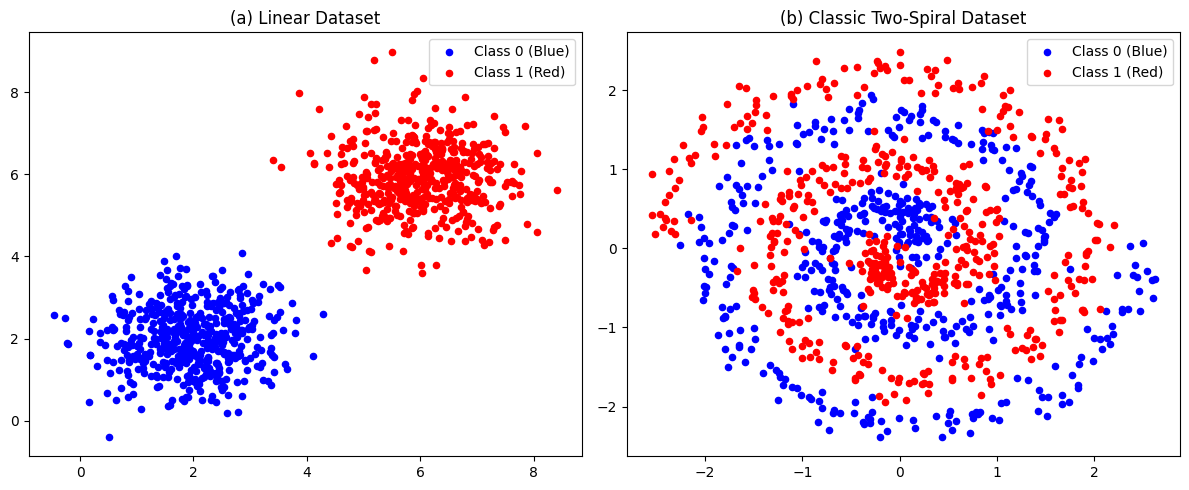

In [54]:
import matplotlib.pyplot as plt
import numpy as np

# Set global random seed to 7 for reproducibility
np.random.seed(7)
n_per_class = 500

# ==========================================
# 1. LINEAR DATASET
# ==========================================
X1_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X2_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X1_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)
X2_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)

X1_lin = np.concatenate([X1_class0, X1_class1])
X2_lin = np.concatenate([X2_class0, X2_class1])
Y_lin = np.array([0] * n_per_class + [1] * n_per_class)
X_lin_matrix = np.column_stack((X1_lin, X2_lin))

# ==========================================
# 2. CLASSIC TWO-SPIRAL DATASET
# ==========================================
t = np.linspace(0, 4 * np.pi, n_per_class)
r = np.linspace(0.2, 2.5, n_per_class)
X_class0_sp = np.column_stack((r * np.cos(t), r * np.sin(t)))
X_class1_sp = np.column_stack((-r * np.cos(t), -r * np.sin(t)))
noise = 0.15

# Add Gaussian noise to create spiral arms
X_class0_sp += np.random.randn(n_per_class, 2) * noise
X_class1_sp += np.random.randn(n_per_class, 2) * noise

X_spiral = np.vstack((X_class0_sp, X_class1_sp))
Y_spiral = np.array([0] * n_per_class + [1] * n_per_class)
X1_spiral, X2_spiral = X_spiral[:, 0], X_spiral[:, 1]

# ==========================================
# PLOT DATASETS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Linear Dataset Plot
axes[0].scatter(X1_lin[Y_lin == 0], X2_lin[Y_lin == 0], c="blue", edgecolors="blue", s=20, label="Class 0 (Blue)")
axes[0].scatter(X1_lin[Y_lin == 1], X2_lin[Y_lin == 1], c="red", edgecolors="red", s=20, label="Class 1 (Red)")
axes[0].set_title("(a) Linear Dataset")
axes[0].legend()

# Classic Spiral Dataset Plot
axes[1].scatter(X1_spiral[Y_spiral == 0], X2_spiral[Y_spiral == 0], c="blue", edgecolors="blue", s=20, label="Class 0 (Blue)")
axes[1].scatter(X1_spiral[Y_spiral == 1], X2_spiral[Y_spiral == 1], c="red", edgecolors="red", s=20, label="Class 1 (Red)")
axes[1].set_title("(b) Classic Two-Spiral Dataset")
axes[1].legend()

plt.tight_layout()
plt.show()

Linear Dataset - Perceptron Accuracy: 100.00%
Linear Dataset - Linear SVM Accuracy: 100.00%


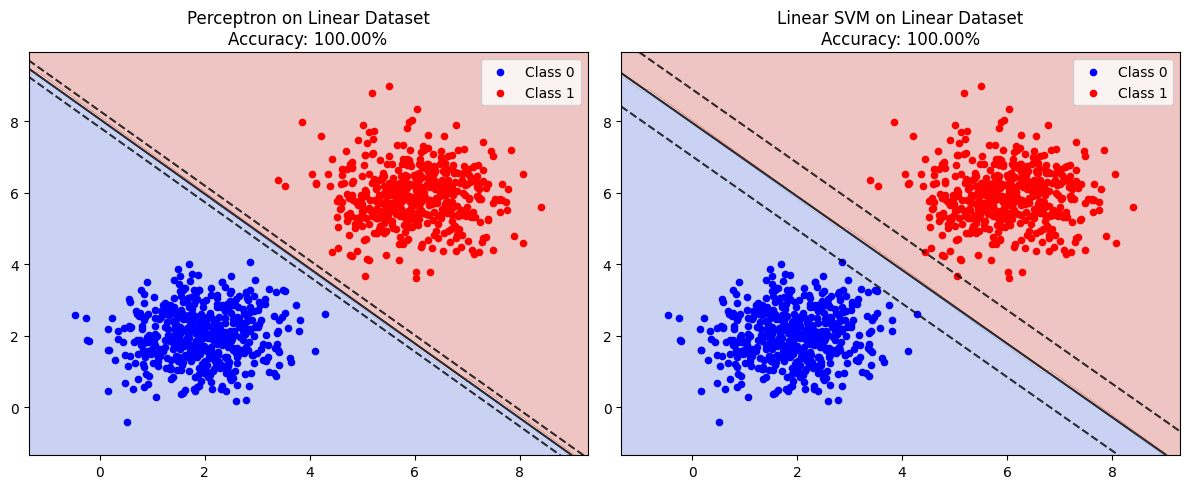

Spiral Dataset - Perceptron Accuracy: 49.50%
Spiral Dataset - Linear SVM Accuracy: 51.90%


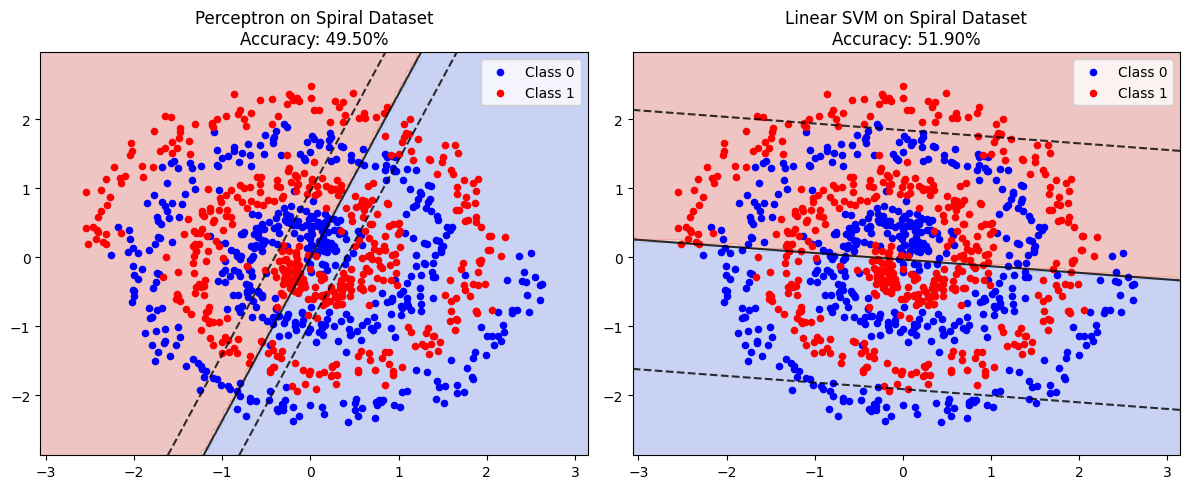

In [55]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np

# Helper function to train, evaluate, and plot models using pre-generated global datasets
def evaluate_classifier(X, Y, dataset_name):
  # Initialize models
  models = {
      "Perceptron": Perceptron(random_state=3),
      "Linear SVM": SVC(kernel="linear", random_state=3),
  }

  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  # Compute boundary margins with padding
  x_min, x_max = X[:, 0].min(), X[:, 0].max()
  y_min, y_max = X[:, 1].min(), X[:, 1].max()
  x_padding = (x_max - x_min) * 0.1
  y_padding = (y_max - y_min) * 0.1
  x_lims = [x_min - x_padding, x_max + x_padding]
  y_lims = [y_min - y_padding, y_max + y_padding]

  for idx, (name, model) in enumerate(models.items()):
    # Train the model
    model.fit(X, Y)

    # Predict and calculate accuracy
    Y_pred = model.predict(X)
    acc = accuracy_score(Y, Y_pred)
    print(f"{dataset_name} - {name} Accuracy: {acc * 100:.2f}%")

    # Plot decision boundary and data points
    ax = axes[idx]

    # Create a dense grid to plot decision boundary and margins
    xx, yy = np.meshgrid(
        np.linspace(x_lims[0], x_lims[1], 100),
        np.linspace(y_lims[0], y_lims[1], 100)
    )
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    # Get predictions or decision function
    if hasattr(model, "decision_function"):
        Z = model.decision_function(grid_points)
        Z_pred = model.predict(grid_points)
        Z_pred = Z_pred.reshape(xx.shape)
        Z = Z.reshape(xx.shape)

        # Plot decision region background
        ax.contourf(xx, yy, Z_pred, cmap=plt.cm.coolwarm, alpha=0.3)
        # Plot separating hyperplane (Z=0) and margin lines (Z = -1, 1)
        contours = ax.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.8, linestyles=['--', '-', '--'])
    else:
        Z_pred = model.predict(grid_points).reshape(xx.shape)
        ax.contourf(xx, yy, Z_pred, cmap=plt.cm.coolwarm, alpha=0.3)
        ax.contour(xx, yy, Z_pred, colors='k', levels=[0.5], linestyles=['-'])

    ax.scatter(
        X[Y == 0, 0],
        X[Y == 0, 1],
        c="blue",
        edgecolors="blue",
        s=20,
        label="Class 0",
    )
    ax.scatter(
        X[Y == 1, 0],
        X[Y == 1, 1],
        c="red",
        edgecolors="red",
        s=20,
        label="Class 1",
    )

    # Apply the boundary limits
    ax.set_xlim(x_lims)
    ax.set_ylim(y_lims)

    ax.set_title(f"{name} on {dataset_name}\nAccuracy: {acc * 100:.2f}%")
    ax.legend()

  plt.tight_layout()
  plt.show()

# Run using the globally loaded datasets
evaluate_classifier(X_lin_matrix, Y_lin, "Linear Dataset")
evaluate_classifier(X_spiral, Y_spiral, "Spiral Dataset")

=== RBF Kernel ===
Accuracy: 94.40%
F1-Score: 0.9441
Confusion Matrix:
 [[471  29]
 [ 27 473]]


=== Polynomial Kernel (Degree 3) ===
Accuracy: 67.70%
F1-Score: 0.6786
Confusion Matrix:
 [[336 164]
 [159 341]]




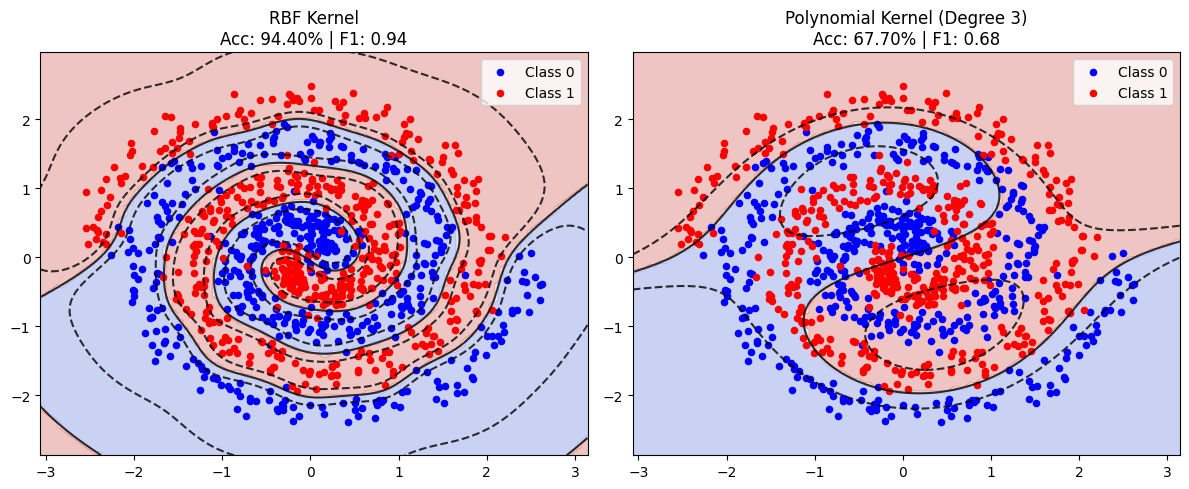

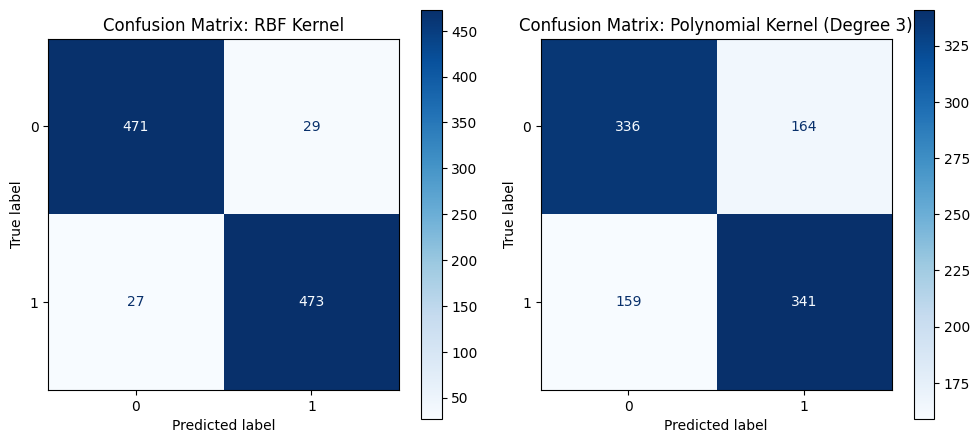

In [56]:
import plotly.graph_objects as go
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.svm import SVC
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# SECTION 2 & 3: TRAINING, EVALUATION & KERNEL COMPARISON
# ==========================================
kernels_to_test = {
    "RBF Kernel": SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7),
    "Polynomial Kernel (Degree 3)": SVC(
        kernel="poly", degree=3, C=10.0, coef0=1, random_state=7
    ),
}

# Set up figures for Decision Boundaries and Visual Confusion Matrices
fig_dec, axes_dec = plt.subplots(1, 2, figsize=(12, 5))
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(10, 4.5))

# Compute limits based on spiral dataset with padding
x_min, x_max = X_spiral[:, 0].min(), X_spiral[:, 0].max()
y_min, y_max = X_spiral[:, 1].min(), X_spiral[:, 1].max()
x_padding = (x_max - x_min) * 0.1
y_padding = (y_max - y_min) * 0.1
x_lims = [x_min - x_padding, x_max + x_padding]
y_lims = [y_min - y_padding, y_max + y_padding]

for idx, (name, model) in enumerate(kernels_to_test.items()):
    # Train model on the pre-existing spiral data
    model.fit(X_spiral, Y_spiral)
    Y_pred = model.predict(X_spiral)

    # Calculate metrics
    acc = accuracy_score(Y_spiral, Y_pred)
    f1 = f1_score(Y_spiral, Y_pred)
    cm = confusion_matrix(Y_spiral, Y_pred)

    print(f"=== {name} ===")
    print(f"Accuracy: {acc * 100:.2f}%")
    print(f"F1-Score: {f1:.4f}")
    print("Confusion Matrix:\n", cm)
    print("\n" + "=" * 30 + "\n")

    # Plot Decision Boundaries
    ax_dec = axes_dec[idx]

    # Generate mesh grid for contour plotting
    xx, yy = np.meshgrid(
        np.linspace(x_lims[0], x_lims[1], 100),
        np.linspace(y_lims[0], y_lims[1], 100)
    )
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    Z_dec = model.decision_function(grid_points).reshape(xx.shape)
    Z_pred = model.predict(grid_points).reshape(xx.shape)

    # Plot filled decision regions
    ax_dec.contourf(xx, yy, Z_pred, cmap=plt.cm.coolwarm, alpha=0.3)
    # Plot separating boundary (0) and margins (-1, 1)
    ax_dec.contour(xx, yy, Z_dec, colors='k', levels=[-1, 0, 1], alpha=0.8, linestyles=['--', '-', '--'])

    ax_dec.scatter(
        X_spiral[Y_spiral == 0, 0],
        X_spiral[Y_spiral == 0, 1],
        c="blue",
        edgecolors="blue",
        s=20,
        label="Class 0",
    )
    ax_dec.scatter(
        X_spiral[Y_spiral == 1, 0],
        X_spiral[Y_spiral == 1, 1],
        c="red",
        edgecolors="red",
        s=20,
        label="Class 1",
    )

    ax_dec.set_xlim(x_lims)
    ax_dec.set_ylim(y_lims)
    ax_dec.set_title(f"{name}\nAcc: {acc * 100:.2f}% | F1: {f1:.2f}")
    ax_dec.legend()

    # Plot Graphical Confusion Matrix
    ax_cm = axes_cm[idx]
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(ax=ax_cm, cmap=plt.cm.Blues, values_format="d")
    ax_cm.set_title(f"Confusion Matrix: {name}")

fig_dec.tight_layout()
fig_cm.tight_layout()
plt.show()

# ==========================================
# 3D INTERACTIVE RENDER
# ==========================================
# Fit RBF model specifically for 3D visualization view
rbf_svm = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
rbf_svm.fit(X_spiral, Y_spiral)

# Use decision function values as the Z-axis coordinate projection
Z_vals = rbf_svm.decision_function(X_spiral)

# Create 3D scatter plot using Plotly
fig_3d = go.Figure(
    data=[
        go.Scatter3d(
            x=X_spiral[Y_spiral == 0, 0],
            y=X_spiral[Y_spiral == 0, 1],
            z=Z_vals[Y_spiral == 0],
            mode="markers",
            marker=dict(size=4, color="blue", opacity=0.9, line=dict(width=1, color="blue")),
            name="Class 0 (Blue)",
        ),
        go.Scatter3d(
            x=X_spiral[Y_spiral == 1, 0],
            y=X_spiral[Y_spiral == 1, 1],
            z=Z_vals[Y_spiral == 1],
            mode="markers",
            marker=dict(size=4, color="red", opacity=0.9, line=dict(width=1, color="red")),
            name="Class 1 (Red)",
        ),
    ]
)

# Add separating hyperplane surface at Z=0
x_range = np.linspace(X_spiral[:, 0].min(), X_spiral[:, 0].max(), 30)
y_range = np.linspace(X_spiral[:, 1].min(), X_spiral[:, 1].max(), 30)
xx, yy = np.meshgrid(x_range, y_range)
zz = np.zeros_like(xx)

fig_3d.add_trace(
    go.Surface(
        x=xx,
        y=yy,
        z=zz,
        colorscale="Viridis",
        opacity=0.4,
        showscale=False,
        name="Separating Hyperplane (Z=0)",
    )
)

fig_3d.update_layout(
    title="Interactive 3D Kernel Projection & Hyperplane (Rotate with your mouse!)",
    scene=dict(
        xaxis_title="X1", yaxis_title="X2", zaxis_title="Decision Value (Z)"
    ),
)

fig_3d.show()

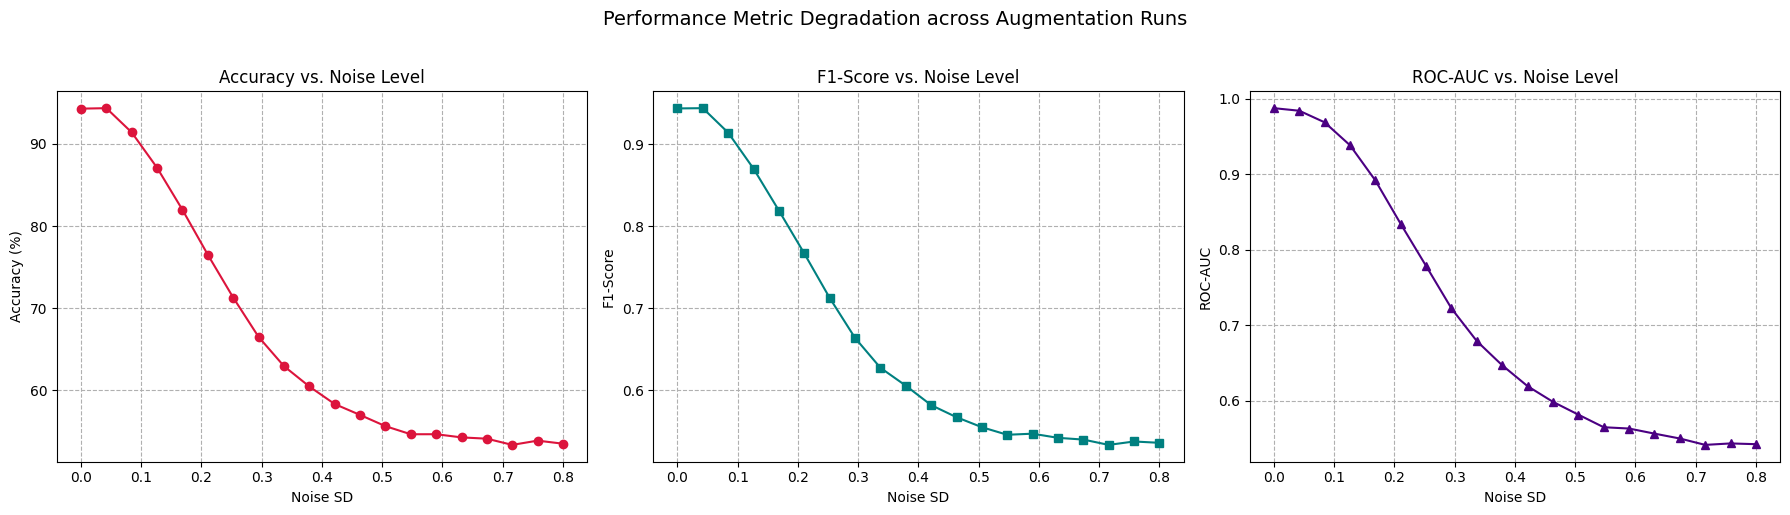

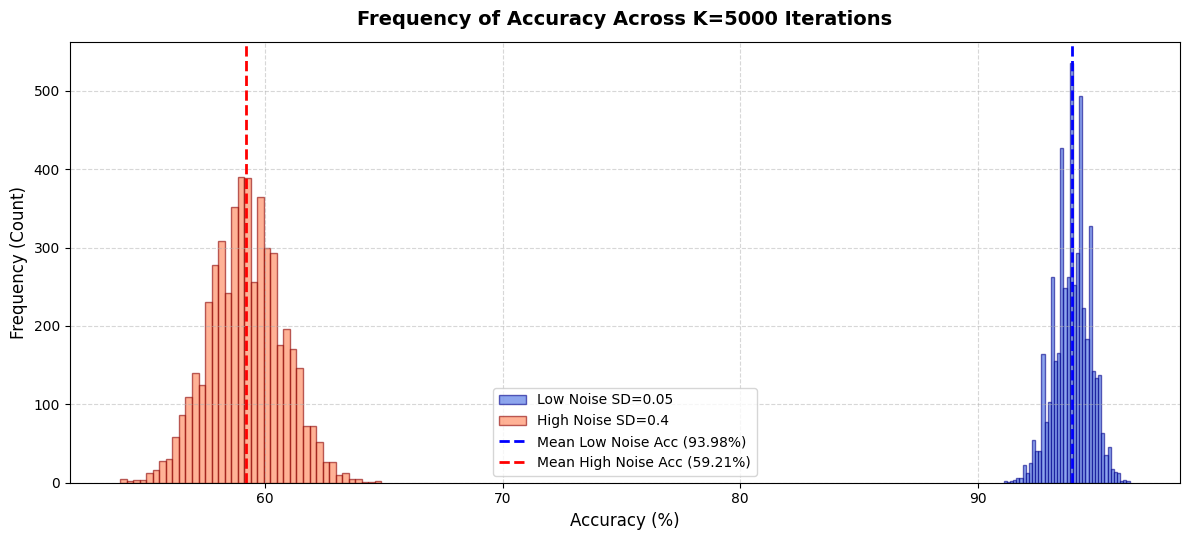

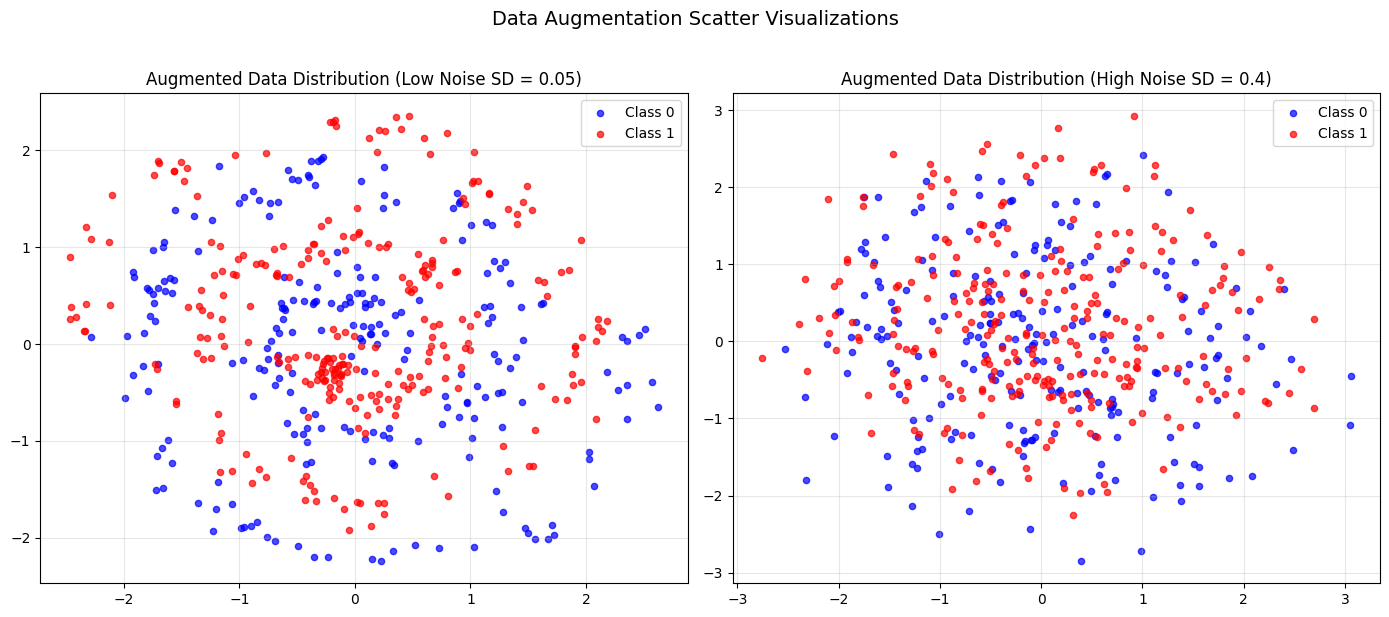

In [57]:
# ==========================================
# SECTION 4: DATA AUGMENTATION & OVERFITTING ANALYSIS
# ==========================================
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

# 1. Ensure best model is fitted on original global spiral data
best_model = SVC(kernel="rbf", C=10.0, gamma=2.0, probability=True, random_state=7)
best_model.fit(X_spiral, Y_spiral)

# 2. Define augmentation evaluation function
def evaluate_augmentation(model, X_orig, Y_orig, noise_sd, k_iterations=100):
    accuracies = []
    f1_scores = []
    roc_aucs = []
    for _ in range(k_iterations):
        # Sample points with replacement from original dataset
        indices = np.random.choice(len(X_orig), size=1000, replace=True)
        X_sample = X_orig[indices]
        Y_sample = Y_orig[indices]

        # Add Gaussian noise
        noise_val = np.random.normal(loc=0.0, scale=noise_sd, size=X_sample.shape)
        X_augmented = X_sample + noise_val

        # Predict and evaluate metrics
        Y_pred = model.predict(X_augmented)
        Y_prob = model.predict_proba(X_augmented)[:, 1]

        accuracies.append(accuracy_score(Y_sample, Y_pred))
        f1_scores.append(f1_score(Y_sample, Y_pred))
        roc_aucs.append(roc_auc_score(Y_sample, Y_prob))
    return np.array(accuracies), np.array(f1_scores), np.array(roc_aucs)

# 3. Run evaluation for Low Noise vs. High Noise over k = 5000 iterations
low_noise_sd = 0.05
high_noise_sd = 0.40
k_runs = 5000

acc_low, f1_low, roc_low = evaluate_augmentation(best_model, X_spiral, Y_spiral, noise_sd=low_noise_sd, k_iterations=k_runs)
acc_high, f1_high, roc_high = evaluate_augmentation(best_model, X_spiral, Y_spiral, noise_sd=high_noise_sd, k_iterations=k_runs)

# 4. Generate curves across a range of noise levels (SD 0.0 to 0.8)
noise_range = np.linspace(0.0, 0.8, 20)
sweep_accs, sweep_f1s, sweep_rocs = [], [], []
for sd in noise_range:
    a, f, r = evaluate_augmentation(best_model, X_spiral, Y_spiral, noise_sd=sd, k_iterations=50)
    sweep_accs.append(a.mean())
    sweep_f1s.append(f.mean())
    sweep_rocs.append(r.mean())

# 5. Plot F1-score, ROC-AUC and Accuracy degradation curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(noise_range, np.array(sweep_accs) * 100, marker='o', color='crimson', label='Accuracy')
axes[0].set_title('Accuracy vs. Noise Level')
axes[0].set_xlabel('Noise SD')
axes[0].set_ylabel('Accuracy (%)')
axes[0].grid(True, linestyle='--')

axes[1].plot(noise_range, sweep_f1s, marker='s', color='teal', label='F1-Score')
axes[1].set_title('F1-Score vs. Noise Level')
axes[1].set_xlabel('Noise SD')
axes[1].set_ylabel('F1-Score')
axes[1].grid(True, linestyle='--')

axes[2].plot(noise_range, sweep_rocs, marker='^', color='indigo', label='ROC-AUC')
axes[2].set_title('ROC-AUC vs. Noise Level')
axes[2].set_xlabel('Noise SD')
axes[2].set_ylabel('ROC-AUC')
axes[2].grid(True, linestyle='--')
plt.suptitle('Performance Metric Degradation across Augmentation Runs', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 6. Frequency Distribution Plot of Accuracy across K=5000 Iterations
plt.figure(figsize=(12, 5.5))
plt.hist(acc_low * 100, bins=40, alpha=0.6, color='royalblue', edgecolor='darkblue', label=f'Low Noise SD={low_noise_sd}')
plt.hist(acc_high * 100, bins=40, alpha=0.6, color='coral', edgecolor='darkred', label=f'High Noise SD={high_noise_sd}')
plt.axvline(np.mean(acc_low) * 100, color='blue', linestyle='dashed', linewidth=2, label=f'Mean Low Noise Acc ({np.mean(acc_low)*100:.2f}%)')
plt.axvline(np.mean(acc_high) * 100, color='red', linestyle='dashed', linewidth=2, label=f'Mean High Noise Acc ({np.mean(acc_high)*100:.2f}%)')
plt.title(f'Frequency of Accuracy Across K={k_runs} Iterations', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Accuracy (%)', fontsize=12)
plt.ylabel('Frequency (Count)', fontsize=12)
plt.legend(fontsize=10, loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 7. Scatter plots of augmented data points under Low SD and High SD
vis_indices = np.random.choice(len(X_spiral), size=500, replace=True)
X_vis_sample = X_spiral[vis_indices]
Y_vis_sample = Y_spiral[vis_indices]

X_vis_low = X_vis_sample + np.random.normal(0.0, low_noise_sd, X_vis_sample.shape)
X_vis_high = X_vis_sample + np.random.normal(0.0, high_noise_sd, X_vis_sample.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Low Noise Scatter
axes[0].scatter(X_vis_low[Y_vis_sample == 0, 0], X_vis_low[Y_vis_sample == 0, 1], c='blue', edgecolors='blue', s=20, alpha=0.7, label='Class 0')
axes[0].scatter(X_vis_low[Y_vis_sample == 1, 0], X_vis_low[Y_vis_sample == 1, 1], c='red', edgecolors='red', s=20, alpha=0.7, label='Class 1')
axes[0].set_title(f'Augmented Data Distribution (Low Noise SD = {low_noise_sd})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# High Noise Scatter
axes[1].scatter(X_vis_high[Y_vis_sample == 0, 0], X_vis_high[Y_vis_sample == 0, 1], c='blue', edgecolors='blue', s=20, alpha=0.7, label='Class 0')
axes[1].scatter(X_vis_high[Y_vis_sample == 1, 0], X_vis_high[Y_vis_sample == 1, 1], c='red', edgecolors='red', s=20, alpha=0.7, label='Class 1')
axes[1].set_title(f'Augmented Data Distribution (High Noise SD = {high_noise_sd})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Data Augmentation Scatter Visualizations', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Noise Level (0.0% shuffled): Accuracy = 94.40%
Noise Level (15.0% shuffled): Accuracy = 93.90%
Noise Level (25.0% shuffled): Accuracy = 90.90%
Noise Level (50.0% shuffled): Accuracy = 49.60%
Noise Level (75.0% shuffled): Accuracy = 8.40%


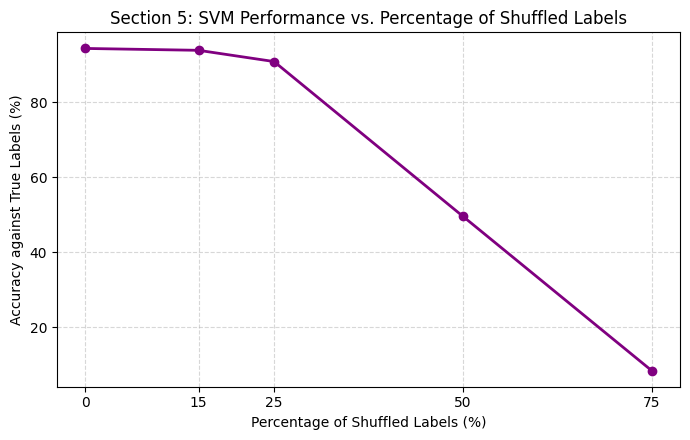

In [58]:
# ==========================================
# SECTION 5: NOISE ANALYSIS (Label Shuffling)
# ==========================================

# Define noise percentages to test
noise_percentages = [0.0, 0.15, 0.25, 0.50, 0.75]
accuracies_noise = []

# Use original global spiral dataset
X_train_base = X_spiral
Y_train_base = Y_spiral.copy()

for p in noise_percentages:
    Y_noisy = Y_train_base.copy()
    num_to_shuffle = int(len(Y_noisy) * p)

    if num_to_shuffle > 0:
        shuffle_indices = np.random.choice(len(Y_noisy), size=num_to_shuffle, replace=False)
        Y_noisy[shuffle_indices] = 1 - Y_noisy[shuffle_indices]

    # Train SVM
    svm_noise = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
    svm_noise.fit(X_train_base, Y_noisy)

    # Evaluate
    Y_pred = svm_noise.predict(X_train_base)
    acc = accuracy_score(Y_train_base, Y_pred)
    accuracies_noise.append(acc * 100)
    print(f"Noise Level ({p*100}% shuffled): Accuracy = {acc * 100:.2f}%")

# Plotting Performance vs. Percentage of Shuffled Labels
plt.figure(figsize=(7, 4.5))
plt.plot([p * 100 for p in noise_percentages], accuracies_noise, marker='o', linestyle='-', color='purple', linewidth=2)
plt.title("Section 5: SVM Performance vs. Percentage of Shuffled Labels")
plt.xlabel("Percentage of Shuffled Labels (%)")
plt.ylabel("Accuracy against True Labels (%)")
plt.xticks([p * 100 for p in noise_percentages])
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

+----------------------------------+
| Dimensions   | Training Accuracy |
+----------------------------------+
| 2            |          94.40% |
| 3            |          97.20% |
| 10           |         100.00% |
+----------------------------------+



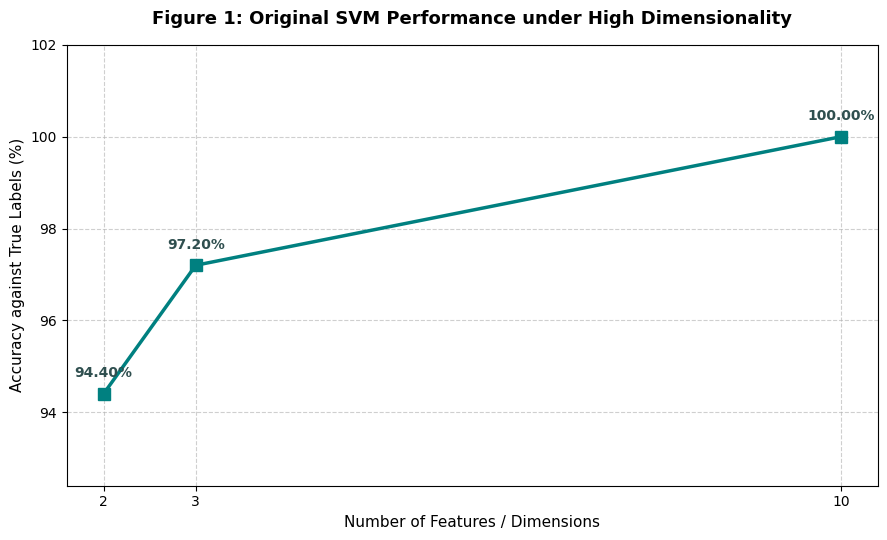

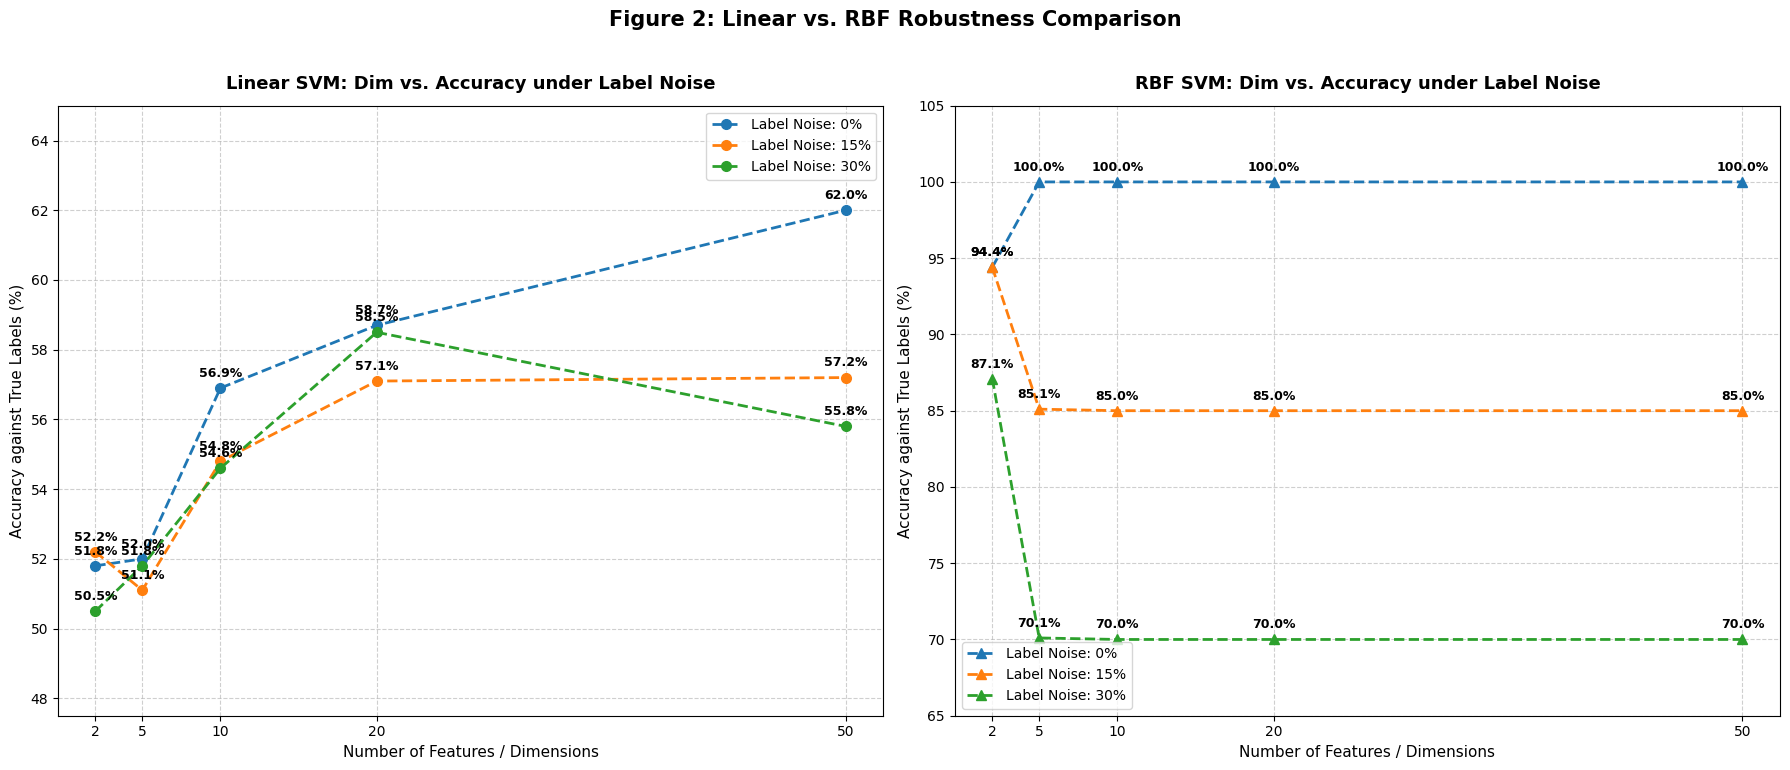

In [59]:
# ==========================================
# SECTION 6: HIGH DIMENSIONALITY ANALYSIS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Define different dimension sizes to test
dimension_sizes = [2, 3, 10]
high_dim_accuracies = []

# Base spiral data
X_base = X_spiral
Y_base = Y_spiral

for d in dimension_sizes:
    if d == 2:
        X_high = X_base.copy()
    else:
        noise_features = np.random.normal(loc=0.0, scale=1.0, size=(X_base.shape[0], d - 2))
        X_high = np.hstack((X_base, noise_features))

    # Train RBF SVM
    svm_high_dim = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
    svm_high_dim.fit(X_high, Y_base)

    # Evaluate performance
    Y_pred = svm_high_dim.predict(X_high)
    acc = accuracy_score(Y_base, Y_pred)
    high_dim_accuracies.append(acc * 100)

# Print a clean text table of results
print("+" + "-"*34 + "+")
print(f"| {'Dimensions':<12} | {'Training Accuracy':<15} |")
print("+" + "-"*34 + "+")
for d, acc in zip(dimension_sizes, high_dim_accuracies):
    print(f"| {d:<12} | {acc:>14.2f}% |")
print("+" + "-"*34 + "+")
print()

# ==========================================
# Dimensionality vs. Test Accuracy under Label Noise
# ==========================================
sweep_dimensions = [2, 5, 10, 20, 50]
noise_rates = [0.0, 0.15, 0.30]

results_linear = {noise: [] for noise in noise_rates}
results_rbf = {noise: [] for noise in noise_rates}

for d in sweep_dimensions:
    if d == 2:
        X_high_sweep = X_base.copy()
    else:
        noise_feats = np.random.normal(loc=0.0, scale=1.0, size=(X_base.shape[0], d - 2))
        X_high_sweep = np.hstack((X_base, noise_feats))

    for noise_rate in noise_rates:
        # Inject label noise
        Y_noisy = Y_base.copy()
        if noise_rate > 0.0:
            num_to_shuffle = int(len(Y_noisy) * noise_rate)
            shuffle_indices = np.random.choice(len(Y_noisy), size=num_to_shuffle, replace=False)
            Y_noisy[shuffle_indices] = 1 - Y_noisy[shuffle_indices]

        # Linear SVM
        clf_linear = SVC(kernel="linear", C=10.0, random_state=7)
        clf_linear.fit(X_high_sweep, Y_noisy)
        acc_lin = accuracy_score(Y_base, clf_linear.predict(X_high_sweep))
        results_linear[noise_rate].append(acc_lin * 100)

        # RBF SVM
        clf_rbf = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
        clf_rbf.fit(X_high_sweep, Y_noisy)
        acc_rbf = accuracy_score(Y_base, clf_rbf.predict(X_high_sweep))
        results_rbf[noise_rate].append(acc_rbf * 100)

# ==========================================
# PLOT 1: ORIGINAL DIMENSION SWEEP (STANDALONE)
# ==========================================
plt.figure(figsize=(9, 5.5))
plt.plot(dimension_sizes, high_dim_accuracies, marker='s', linestyle='-', color='teal', linewidth=2.5, markersize=8)
plt.title("Figure 1: Original SVM Performance under High Dimensionality", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Number of Features / Dimensions", fontsize=11)
plt.ylabel("Accuracy against True Labels (%)", fontsize=11)
plt.xticks(dimension_sizes)
plt.ylim(min(high_dim_accuracies) - 2, max(high_dim_accuracies) + 2)
plt.grid(True, linestyle="--", alpha=0.6)

# Annotate exact accuracy scores directly on the line plot with clear styling
for d, acc in zip(dimension_sizes, high_dim_accuracies):
    plt.annotate(f"{acc:.2f}%", (d, acc), textcoords="offset points", xytext=(0,12), ha='center', fontweight='bold', color='darkslategray', fontsize=10)

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 2: LINEAR VS RBF COMPARISON UNDER NOISE (1X2 SUBPLOT)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Graph A: Linear SVM under Label Noise
for noise_rate, accs in results_linear.items():
    axes[0].plot(sweep_dimensions, accs, marker='o', linestyle='--', linewidth=2, markersize=7, label=f"Label Noise: {int(noise_rate*100)}%")
    for d, acc in zip(sweep_dimensions, accs):
        axes[0].annotate(f"{acc:.1f}%", (d, acc), textcoords="offset points", xytext=(0,8), ha='center', fontsize=9, fontweight='bold')

axes[0].set_title("Linear SVM: Dim vs. Accuracy under Label Noise", fontsize=13, pad=12, fontweight='bold')
axes[0].set_xlabel("Number of Features / Dimensions", fontsize=11)
axes[0].set_ylabel("Accuracy against True Labels (%)", fontsize=11)
axes[0].set_xticks(sweep_dimensions)
axes[0].set_ylim(min([min(v) for v in results_linear.values()]) - 3, max([max(v) for v in results_linear.values()]) + 3)
axes[0].legend(fontsize=10, loc='best')
axes[0].grid(True, linestyle="--", alpha=0.6)

# Graph B: RBF SVM under Label Noise
for noise_rate, accs in results_rbf.items():
    axes[1].plot(sweep_dimensions, accs, marker='^', linestyle='--', linewidth=2, markersize=7, label=f"Label Noise: {int(noise_rate*100)}%")
    for d, acc in zip(sweep_dimensions, accs):
        axes[1].annotate(f"{acc:.1f}%", (d, acc), textcoords="offset points", xytext=(0,8), ha='center', fontsize=9, fontweight='bold')

axes[1].set_title("RBF SVM: Dim vs. Accuracy under Label Noise", fontsize=13, pad=12, fontweight='bold')
axes[1].set_xlabel("Number of Features / Dimensions", fontsize=11)
axes[1].set_ylabel("Accuracy against True Labels (%)", fontsize=11)
axes[1].set_xticks(sweep_dimensions)
axes[1].set_ylim(min([min(v) for v in results_rbf.values()]) - 5, max([max(v) for v in results_rbf.values()]) + 5)
axes[1].legend(fontsize=10, loc='best')
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 2: Linear vs. RBF Robustness Comparison", fontsize=15, y=1.02, fontweight='bold')
plt.tight_layout()
plt.show()

+------------------------------------------------------+
| Metric       | Threshold  | Max Tolerable Noise (SD) |
+------------------------------------------------------+
| Accuracy     | 0.7        | 0.295                    |
| F1-Score     | 0.7        | 0.295                    |
| ROC-AUC      | 0.7        | 0.337                    |
+------------------------------------------------------+


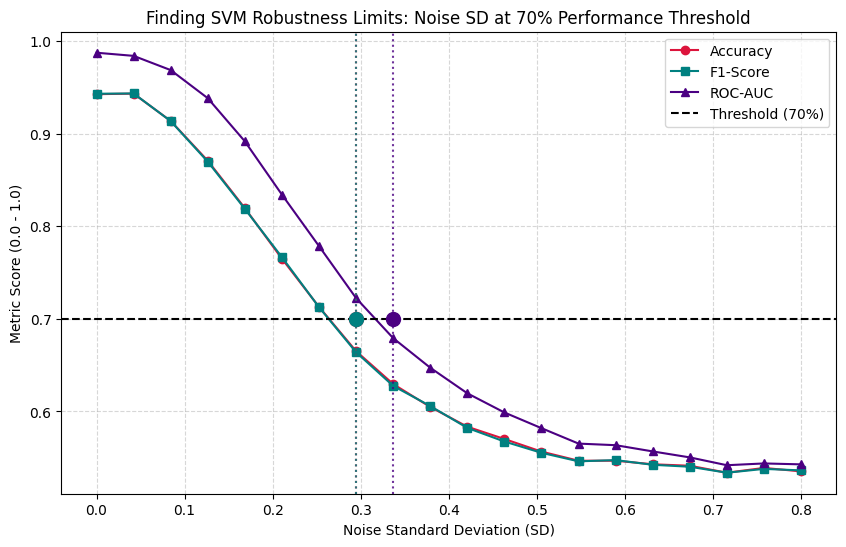

In [61]:
import numpy as np
import matplotlib.pyplot as plt

# Define the threshold (70%)
threshold = 0.70

# Convert accuracy sweep to proportion for consistent comparison
sweep_accs_prop = np.array(sweep_accs)
sweep_f1s_arr = np.array(sweep_f1s)
sweep_rocs_arr = np.array(sweep_rocs)

# Find the first index where performance drops below the threshold
def find_threshold_crossing(metric_values, noise_range, threshold):
    for i, val in enumerate(metric_values):
        if val < threshold:
            return noise_range[i], val
    return None, None

acc_noise_limit, acc_val = find_threshold_crossing(sweep_accs_prop, noise_range, threshold)
f1_noise_limit, f1_val = find_threshold_crossing(sweep_f1s_arr, noise_range, threshold)
roc_noise_limit, roc_val = find_threshold_crossing(sweep_rocs_arr, noise_range, threshold)

# Print the results in a clean table
print("+" + "-"*54 + "+")
print(f"| {'Metric':<12} | {'Threshold':<10} | {'Max Tolerable Noise (SD)':<24} |")
print("+" + "-"*54 + "+")
for name, limit, val in [
    ("Accuracy", acc_noise_limit, acc_val),
    ("F1-Score", f1_noise_limit, f1_val),
    ("ROC-AUC", roc_noise_limit, roc_val)
]:
    limit_str = f"{limit:.3f}" if limit is not None else "N/A (Never below)"
    val_str = f"{val*100:.1f}%" if name == "Accuracy" and val is not None else (f"{val:.3f}" if val is not None else "N/A")
    print(f"| {name:<12} | {threshold:<10} | {limit_str:<24} |")
print("+" + "-"*54 + "+")

# Visualize the thresholds
plt.figure(figsize=(10, 6))
plt.plot(noise_range, sweep_accs_prop, label='Accuracy', marker='o', color='crimson')
plt.plot(noise_range, sweep_f1s_arr, label='F1-Score', marker='s', color='teal')
plt.plot(noise_range, sweep_rocs_arr, label='ROC-AUC', marker='^', color='indigo')
plt.axhline(y=threshold, color='black', linestyle='--', label=f'Threshold ({int(threshold*100)}%)')

# Highlight crossing points
for limit, label, color in [(acc_noise_limit, 'Acc Limit', 'crimson'), (f1_noise_limit, 'F1 Limit', 'teal'), (roc_noise_limit, 'ROC Limit', 'indigo')]:
    if limit is not None:
        plt.axvline(x=limit, color=color, linestyle=':', alpha=0.8)
        plt.scatter(limit, threshold, color=color, s=100, zorder=5)

plt.title("Finding SVM Robustness Limits: Noise SD at 70% Performance Threshold")
plt.xlabel("Noise Standard Deviation (SD)")
plt.ylabel("Metric Score (0.0 - 1.0)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()